<a href="https://colab.research.google.com/github/guri19006/project-2026/blob/main/Agriculture_Crop_Yield_Analysis_Colab_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Agriculture & Crop Yield Analysis
### A Data Analytics Approach using FAOSTAT (QCL) Data

**Student:** Gurshan Singh Gill  |  **Reg. No.:** 72413481  
**Programme:** B.Tech CSE (AI & DS), CT University, Ludhiana  
**Training Organisation:** Future Finders, Mohali

---
**What this notebook does:**

1. Acquire the FAOSTAT *Crops and Livestock Products (QCL)* dataset (auto-download, or upload manually)
2. Clean & standardise data for India (units, aggregates, missing/derived yield)
3. Statistical analysis (mean, CV, linear trend, R², p-value, log-linear growth, production drivers)
4. Eight visualisations
5. SQLite database + analytical SQL queries
6. Power BI-ready CSV exports
7. Auto-generated analysis summary + one-click ZIP download



## 1. Setup & Configuration

In [ ]:
%pip -q install seaborn scipy

In [ ]:
import os, re, zipfile, shutil, sqlite3, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Google Colab:", IN_COLAB)

Running in Google Colab: True


In [ ]:
COUNTRY   = "India"
MIN_YEARS = 10
TOP_N     = 10
DRIVER_WINDOW = 5
USE_SYNTHETIC_DEMO = False

FAOSTAT_URL = ("https://bulks-faostat.fao.org/production/"
               "Production_Crops_Livestock_E_All_Data_(Normalized).zip")

# folder structure
BASE     = Path("agriculture_project")
RAW_DIR  = BASE / "data" / "raw"
OUT_DIR  = BASE / "outputs"
FIG_DIR  = OUT_DIR / "figures"
SQL_DIR  = OUT_DIR / "sql_results"
DB_DIR   = BASE / "database"
PBI_DIR  = BASE / "powerbi" / "data"
for d in (RAW_DIR, FIG_DIR, SQL_DIR, DB_DIR, PBI_DIR):
    d.mkdir(parents=True, exist_ok=True)

TAG = "SYNTHETIC DEMO DATA - NOT REAL FINDINGS" if USE_SYNTHETIC_DEMO else ""
print("Folders ready under:", BASE.resolve())

Folders ready under: /content/agriculture_project


## 2. Data Acquisition
The notebook first looks for an existing file in `data/raw`, then tries to download from FAOSTAT, and finally (in Colab) asks you to upload the file.

> Manual download: <https://www.fao.org/faostat/en/#data/QCL> → *Bulk downloads* → **"Production_Crops_Livestock_E_All_Data_(Normalized).zip"**

In [ ]:
SKIP_NAMES = ("flags", "areacodes", "itemcodes", "itemgroupcodes", "symbol")

def find_raw_file():
    for p in sorted(RAW_DIR.glob("*.csv")):
        if not any(s in p.name.lower() for s in SKIP_NAMES):
            return p
    return None

def extract_zip(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        members = [m for m in z.namelist()
                   if m.lower().endswith(".csv") and not any(s in m.lower() for s in SKIP_NAMES)]
        if not members:
            raise FileNotFoundError("No suitable CSV inside the ZIP.")
        target = members[0]
        z.extract(target, RAW_DIR)
        return RAW_DIR / target

def download_faostat():
    zip_path = RAW_DIR / "faostat_qcl.zip"
    try:
        print("Downloading FAOSTAT QCL (this can take a minute)...")
        req = urllib.request.Request(FAOSTAT_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=180) as r, open(zip_path, "wb") as f:
            shutil.copyfileobj(r, f)
        path = extract_zip(zip_path)
        print("Downloaded & extracted:", path.name)
        return path
    except Exception as e:
        print("Automatic download failed:", repr(e))
        return None

def upload_file():
    print("Please upload the FAOSTAT QCL file (.csv or .zip)...")
    uploaded = files.upload()
    for name in uploaded:
        dest = RAW_DIR / name
        with open(dest, "wb") as f:
            f.write(uploaded[name])
        if name.lower().endswith(".zip"):
            return extract_zip(dest)
        return dest
    return None

def make_synthetic_demo():
    """Invented data in FAOSTAT 'normalized' layout. ONLY for testing the code."""
    rng = np.random.default_rng(42)
    rows, years = [], range(1961, 2023)
    crops = {"Demo Crop A": (30000, 1500), "Demo Crop B": (12000, 2200), "Demo Crop C": (5000, 900),
             "Demo Crop D": (800, 700), "Demo Crop E": (2500, 3100), "Demo Crop F": (9000, 1100)}
    for country in (COUNTRY, "Other Country"):
        for crop, (a0, y0) in crops.items():
            g = rng.uniform(0.005, 0.02)
            for i, yr in enumerate(years):
                area = a0 * 1000 * (1 + 0.004 * i) * rng.uniform(0.95, 1.05)
                yld = y0 * (1 + g) ** i * rng.uniform(0.92, 1.08)          # kg/ha
                prod = area * yld / 1000                                   # tonnes
                for el, unit, val in (("Area harvested", "ha", area),
                                      ("Yield", "hg/ha", yld * 10),
                                      ("Production", "tonnes", prod)):
                    if el == "Yield" and crop == "Demo Crop D" and yr % 7 == 0:
                        continue   # missing reported yield -> must be derived
                    rows.append([country, crop, el, yr, unit, val, "E"])
    for yr in years:   # aggregate + livestock rows that must be excluded
        rows.append([COUNTRY, "Cereals, primary", "Production", yr, "tonnes", 1e8, "A"])
        rows.append([COUNTRY, "Demo Milk", "Production", yr, "tonnes", 5e7, "A"])
    df = pd.DataFrame(rows, columns=["Area", "Item", "Element", "Year", "Unit", "Value", "Flag"])
    path = RAW_DIR / "Synthetic_Demo_Normalized.csv"
    df.to_csv(path, index=False)
    return path

raw_file = None
if USE_SYNTHETIC_DEMO:
    print("⚠️  SYNTHETIC DEMO MODE - results are NOT real agricultural findings.")
    raw_file = make_synthetic_demo()
else:
    raw_file = find_raw_file() or download_faostat()
    if raw_file is None and IN_COLAB:
        raw_file = upload_file()

if raw_file is None:
    raise FileNotFoundError("No FAOSTAT file available. Upload it to data/raw or fix network access.")
print("Using raw file:", raw_file)

Downloaded & extracted: Production_Crops_Livestock_E_All_Data_(Normalized).csv
Using raw file: agriculture_project/data/raw/Production_Crops_Livestock_E_All_Data_(Normalized).csv


## 3. Data Cleaning & Standardisation
* Supports **normalized** and **wide** FAOSTAT layouts
* Filters to the selected country and the three measures: *Area harvested*, *Production*, *Yield*
* Converts units → hectares, tonnes, kg/ha (unsupported units, e.g. livestock yields, are dropped & reported)
* Removes missing/negative values and **aggregate** categories (e.g. "Cereals, primary")
* Derives yield = production ÷ area **only** when reported yield is missing (flagged as `derived`)
* Drops crops with fewer than `MIN_YEARS` yield observations

In [ ]:
UNIT_FACTORS = {
    "area_ha":     {"ha": 1.0, "1000 ha": 1000.0},
    "production_t":{"t": 1.0, "tonnes": 1.0, "1000 t": 1000.0, "1000 tonnes": 1000.0},
    "yield_kg_ha": {"kg/ha": 1.0, "hg/ha": 0.1, "100 g/ha": 0.1, "100g/ha": 0.1, "t/ha": 1000.0},
}
ELEMENT_MAP = {"area harvested": "area_ha", "production": "production_t", "yield": "yield_kg_ha"}
AGGREGATE_RE = re.compile(r"\b(total|primary|equivalent)\b", flags=re.I)


def load_and_clean(path, country=COUNTRY, min_years=MIN_YEARS):
    report = {}
    raw = pd.read_csv(path, encoding="latin-1", low_memory=False)
    raw.columns = [c.strip() for c in raw.columns]
    report["raw_rows"] = len(raw)

    # wide layout -> normalized
    year_cols = [c for c in raw.columns if re.fullmatch(r"Y\d{4}", c)]
    if year_cols:
        id_vars = [c for c in raw.columns
                   if c not in year_cols and not re.fullmatch(r"Y\d{4}[FN]", c)]
        raw = raw[id_vars + year_cols].melt(id_vars=id_vars, var_name="Year", value_name="Value")
        raw["Year"] = raw["Year"].str[1:]

    need = ["Area", "Item", "Element", "Year", "Unit", "Value"]
    missing = [c for c in need if c not in raw.columns]
    if missing:
        raise ValueError(f"Unsupported layout. Missing columns {missing}. Found: {list(raw.columns)}")

    # country filter
    raw["Area"] = raw["Area"].astype(str).str.strip()
    df = raw[raw["Area"].str.lower() == country.lower()].copy()
    if df.empty:
        sample = sorted(raw["Area"].unique())[:15]
        raise ValueError(f"No rows for '{country}'. Example areas: {sample}")
    report["country_rows"] = len(df)

    #  measure filter
    df["measure"] = df["Element"].astype(str).str.strip().str.lower().map(ELEMENT_MAP)
    df = df.dropna(subset=["measure"]).copy()
    report["rows_after_measure_filter"] = len(df)

    # aggregates
    df["Item"] = df["Item"].astype(str).str.strip()
    is_agg = df["Item"].str.contains(AGGREGATE_RE)
    excluded = (df[is_agg][["Item"]].drop_duplicates().assign(reason="aggregate category")
                .reset_index(drop=True))
    df = df[~is_agg].copy()

    # units
    df["unit_clean"] = df["Unit"].astype(str).str.strip().str.lower()
    df["factor"] = [UNIT_FACTORS[m].get(u, np.nan) for m, u in zip(df["measure"], df["unit_clean"])]
    report["rows_unsupported_unit"] = int(df["factor"].isna().sum())
    df = df.dropna(subset=["factor"]).copy()

    # values
    df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
    report["rows_missing_value_or_year"] = int(df[["Year", "Value"]].isna().any(axis=1).sum())
    df = df.dropna(subset=["Year", "Value"])
    report["rows_negative_value"] = int((df["Value"] < 0).sum())
    df = df[df["Value"] >= 0].copy()
    df["Year"] = df["Year"].astype(int)
    df["std_value"] = df["Value"] * df["factor"]

    # reshape: one row per crop-year
    wide = (df.pivot_table(index=["Item", "Year"], columns="measure",
                           values="std_value", aggfunc="first").reset_index())
    wide.columns.name = None
    for c in ("area_ha", "production_t", "yield_kg_ha"):
        if c not in wide.columns:
            wide[c] = np.nan
    wide = wide.rename(columns={"Item": "crop", "Year": "year"})

    # snapshot of missingness BEFORE deriving yield (used in Figure 8)
    missing_df = (wide[["area_ha", "production_t", "yield_kg_ha"]].isna().mean() * 100
                  ).rename("missing_pct").reset_index().rename(columns={"index": "variable"})

    # derive yield where not reported
    wide["yield_source"] = np.where(wide["yield_kg_ha"].notna(), "reported", "")
    can_derive = (wide["yield_kg_ha"].isna() & wide["production_t"].notna()
                  & wide["area_ha"].notna() & (wide["area_ha"] > 0))
    wide.loc[can_derive, "yield_kg_ha"] = wide.loc[can_derive, "production_t"] * 1000 / wide.loc[can_derive, "area_ha"]
    wide.loc[can_derive, "yield_source"] = "derived"
    report["yield_values_derived"] = int(can_derive.sum())

    wide = wide[wide["yield_kg_ha"].notna() & (wide["yield_kg_ha"] > 0)].copy()

    # minimum-years filter
    counts = wide.groupby("crop")["year"].nunique()
    too_few = counts[counts < min_years].index
    if len(too_few):
        excluded = pd.concat([excluded, pd.DataFrame({"Item": too_few,
                              "reason": f"fewer than {min_years} yield years"})], ignore_index=True)
    wide = wide[~wide["crop"].isin(too_few)].sort_values(["crop", "year"]).reset_index(drop=True)

    report["final_rows"] = len(wide)
    report["final_crops"] = wide["crop"].nunique()
    report["year_min"], report["year_max"] = int(wide["year"].min()), int(wide["year"].max())
    return wide, report, excluded, missing_df


clean, clean_report, excluded_items, missing_df = load_and_clean(raw_file)

cleaning_report = pd.DataFrame(list(clean_report.items()), columns=["metric", "value"])
cleaning_report.to_csv(OUT_DIR / "cleaning_report.csv", index=False)
excluded_items.to_csv(OUT_DIR / "excluded_items.csv", index=False)
missing_df.to_csv(OUT_DIR / "missing_values.csv", index=False)

display(cleaning_report)
print("\nExcluded items (sample):")
display(excluded_items.head(15))
print("\nCleaned data preview:")
display(clean.head(10))

,metric,value
0,raw_rows,4209110
1,country_rows,26432
2,rows_after_measure_filter,22272
3,rows_unsupported_unit,128
4,rows_missing_value_or_year,549
5,rows_negative_value,0
6,yield_values_derived,0
7,final_rows,5020
8,final_crops,84
9,year_min,1961



Excluded items (sample):


,Item,reason
0,Natural rubber in primary forms,aggregate category
1,"Beef and Buffalo Meat, primary",aggregate category
2,"Cereals, primary",aggregate category
3,"Citrus Fruit, Total",aggregate category
4,Eggs Primary,aggregate category
5,"Fibre Crops, Fibre Equivalent",aggregate category
6,Fruit Primary,aggregate category
7,"Meat, Total",aggregate category
8,"Milk, Total",aggregate category
9,"Oilcrops, Cake Equivalent",aggregate category



Cleaned data preview:


,crop,year,area_ha,production_t,yield_kg_ha,yield_source
0,"Almonds, in shell",2011,"23,000.00","14,000.00",608.70,reported
1,"Almonds, in shell",2012,"22,000.00","4,000.00",181.80,reported
2,"Almonds, in shell",2013,"21,000.00","9,000.00",428.60,reported
3,"Almonds, in shell",2014,"21,000.00","13,000.00",619.00,reported
4,"Almonds, in shell",2015,"21,000.00","10,000.00",476.20,reported
5,"Almonds, in shell",2016,"11,685.00","7,933.00",678.90,reported
6,"Almonds, in shell",2017,"12,075.00","7,061.00",584.80,reported
7,"Almonds, in shell",2018,"10,584.00","13,688.00","1,293.30",reported
8,"Almonds, in shell",2019,"10,432.00","10,967.00","1,051.30",reported
9,"Almonds, in shell",2020,"8,954.00","10,874.00","1,214.40",reported


## 4. Exploratory & Statistical Analysis
Crop-level summary (mean yield, CV, linear trend slope / R² / p-value, log-linear annual growth for yield, production and area), yearly totals, decade yields and production-driver decomposition.



In [ ]:
def linear_trend(x, y):
    m = (~np.isnan(x)) & (~np.isnan(y))
    if m.sum() < 3:
        return np.nan, np.nan, np.nan
    r = stats.linregress(x[m], y[m])
    return r.slope, r.rvalue ** 2, r.pvalue

def log_growth_pct(x, y):
    """Compound annual growth (%) from slope of ln(y) ~ year."""
    m = (~np.isnan(x)) & (~np.isnan(y)) & (y > 0)
    if m.sum() < 3:
        return np.nan
    slope = stats.linregress(x[m], np.log(y[m])).slope
    return (np.exp(slope) - 1) * 100

def crop_summary_table(df):
    rows = []
    for crop, g in df.groupby("crop"):
        yr = g["year"].values.astype(float)
        y = g["yield_kg_ha"].values
        slope, r2, p = linear_trend(yr, y)
        rows.append({
            "crop": crop, "n_years": len(g),
            "first_year": int(g.year.min()), "last_year": int(g.year.max()),
            "mean_yield_kg_ha": y.mean(), "std_yield": y.std(ddof=1) if len(y) > 1 else np.nan,
            "cv_pct": (y.std(ddof=1) / y.mean() * 100) if len(y) > 1 else np.nan,
            "latest_yield_kg_ha": g.sort_values("year")["yield_kg_ha"].iloc[-1],
            "trend_slope_kg_ha_per_year": slope, "trend_r2": r2, "trend_p_value": p,
            "yield_growth_pct_per_year": log_growth_pct(yr, y),
            "production_growth_pct_per_year": log_growth_pct(yr, g["production_t"].values),
            "area_growth_pct_per_year": log_growth_pct(yr, g["area_ha"].values),
            "mean_production_t": g["production_t"].mean(),
            "mean_area_ha": g["area_ha"].mean(),
        })
    return pd.DataFrame(rows).sort_values("mean_production_t", ascending=False).reset_index(drop=True)

crop_summary = crop_summary_table(clean)
crop_summary.to_csv(OUT_DIR / "crop_summary.csv", index=False)
display(crop_summary.head(15))

,crop,n_years,first_year,last_year,mean_yield_kg_ha,std_yield,cv_pct,latest_yield_kg_ha,trend_slope_kg_ha_per_year,trend_r2,trend_p_value,yield_growth_pct_per_year,production_growth_pct_per_year,area_growth_pct_per_year,mean_production_t,mean_area_ha
0,Sugar cane,64,1961,2024,"61,922.73","11,596.78",18.73,"78,953.00",586.38,0.89,0.00,0.98,2.44,1.44,"239,227,829.86","3,695,566.59"
1,Rice,64,1961,2024,"2,643.23",887.00,33.56,"4,313.20",46.83,0.97,0.00,1.86,2.27,0.40,"112,294,444.99","41,480,071.34"
2,Wheat,64,1961,2024,"2,194.59",848.76,38.68,"3,559.00",45.04,0.98,0.00,2.35,3.71,1.32,"56,760,744.58","23,834,705.47"
3,Potatoes,64,1961,2024,"15,799.24","5,457.21",34.54,"24,568.40",287.08,0.96,0.00,2.00,5.15,3.08,"21,885,077.25","1,181,889.52"
4,"Other vegetables, fresh n.e.c.",64,1961,2024,"10,135.83","2,746.21",27.09,"14,724.80",139.29,0.89,0.00,1.39,0.95,-0.44,"20,687,199.89","2,086,276.23"
5,Bananas,64,1961,2024,"24,290.24","9,268.74",38.16,"39,658.00",469.46,0.89,0.00,2.02,5.00,2.91,"13,747,976.75","477,231.86"
6,Maize (corn),64,1961,2024,"1,750.42",756.90,43.24,"3,544.80",38.15,0.88,0.00,2.16,3.35,1.17,"13,212,390.37","6,857,072.73"
7,"Mangoes, guavas and mangosteens",64,1961,2024,"8,432.89","1,282.18",15.20,"10,068.80",-0.52,0.00,0.95,-0.03,2.39,2.42,"12,904,084.68","1,554,038.92"
8,Millet,64,1961,2024,782.49,332.13,42.45,"1,431.40",16.69,0.88,0.00,2.16,0.66,-1.46,"10,103,806.18","14,363,188.11"
9,Sorghum,64,1961,2024,755.02,181.13,23.99,"1,173.80",8.57,0.78,0.00,1.19,-1.32,-2.48,"8,381,685.89","12,074,993.84"


In [ ]:
# yearly totals
yearly_totals = (clean.groupby("year")
                 .agg(total_production_t=("production_t", "sum"),
                      total_area_ha=("area_ha", "sum"),
                      mean_yield_kg_ha=("yield_kg_ha", "mean"),
                      n_crops=("crop", "nunique"))
                 .reset_index())
yearly_totals.to_csv(OUT_DIR / "yearly_totals.csv", index=False)

# decade-level yield
clean["decade"] = (clean["year"] // 10) * 10
decade_yield = (clean.groupby(["crop", "decade"])["yield_kg_ha"].mean().reset_index())
first_dec = decade_yield.sort_values("decade").groupby("crop")["yield_kg_ha"].transform("first")
decade_yield["yield_index"] = decade_yield["yield_kg_ha"] / first_dec * 100   # first decade = 100
decade_yield.to_csv(OUT_DIR / "decade_yield.csv", index=False)

# production drivers: area effect vs yield effect
def production_drivers(df, window=DRIVER_WINDOW):
    rows = []
    full = df.dropna(subset=["area_ha", "production_t", "yield_kg_ha"])
    full = full[(full.area_ha > 0) & (full.production_t > 0)]
    for crop, g in full.groupby("crop"):
        g = g.sort_values("year")
        if len(g) < 2 * window:
            continue
        a0, a1 = g.area_ha.head(window).mean(), g.area_ha.tail(window).mean()
        p0, p1 = g.production_t.head(window).mean(), g.production_t.tail(window).mean()
        y0, y1 = g.yield_kg_ha.head(window).mean(), g.yield_kg_ha.tail(window).mean()
        d_p, d_a, d_y = np.log(p1 / p0) * 100, np.log(a1 / a0) * 100, np.log(y1 / y0) * 100
        rows.append({"crop": crop,
                     "period_start": f"{g.year.min()}-{g.year.iloc[window-1]}",
                     "period_end": f"{g.year.iloc[-window]}-{g.year.max()}",
                     "production_change_logpts": d_p, "area_effect_logpts": d_a,
                     "yield_effect_logpts": d_y, "residual_logpts": d_p - d_a - d_y,
                     "dominant_driver": "Yield" if abs(d_y) >= abs(d_a) else "Area",
                     "mean_production_t": g.production_t.mean()})
    return pd.DataFrame(rows).sort_values("mean_production_t", ascending=False).reset_index(drop=True)

production_drivers_df = production_drivers(clean)
production_drivers_df.to_csv(OUT_DIR / "production_drivers.csv", index=False)

# yield year-over-year change correlations
yield_wide = clean.pivot(index="year", columns="crop", values="yield_kg_ha")
yoy = yield_wide.pct_change(fill_method=None) * 100
top_crops = crop_summary["crop"].head(TOP_N).tolist()
yoy_corr = yoy[top_crops].corr(min_periods=10)
yoy_corr.to_csv(OUT_DIR / "yield_yoy_correlation.csv")

print("Yearly totals (head):");      display(yearly_totals.head())
print("Production drivers (head):"); display(production_drivers_df.head(10))

Yearly totals (head):


,year,total_production_t,total_area_ha,mean_yield_kg_ha,n_crops
0,1961,"264,473,574.00","150,875,586.00","5,421.69",74
1,1962,"258,786,639.00","154,543,749.00","5,131.89",75
2,1963,"251,739,340.00","154,188,492.00","5,148.54",75
3,1964,"267,762,567.00","155,773,170.00","5,164.27",75
4,1965,"274,447,979.00","154,210,722.00","5,318.42",75


Production drivers (head):


,crop,period_start,period_end,production_change_logpts,area_effect_logpts,yield_effect_logpts,residual_logpts,dominant_driver,mean_production_t
0,Sugar cane,1961-1965,2020-2024,140.04,78.60,61.59,-0.15,Area,"239,227,829.86"
1,Rice,1961-1965,2020-2024,133.01,28.04,104.94,0.04,Yield,"112,294,444.99"
2,Wheat,1961-1965,2020-2024,228.36,84.62,143.72,0.03,Yield,"56,760,744.58"
3,Potatoes,1961-1965,2020-2024,293.12,172.24,121.11,-0.24,Area,"21,885,077.25"
4,"Other vegetables, fresh n.e.c.",1961-1965,2020-2024,67.35,-14.08,81.36,0.07,Yield,"20,687,199.89"
5,Bananas,1961-1965,2020-2024,257.83,160.66,97.46,-0.28,Area,"13,747,976.75"
6,Maize (corn),1961-1965,2020-2024,203.23,81.48,121.60,0.15,Yield,"13,212,390.37"
7,"Mangoes, guavas and mangosteens",1961-1965,2020-2024,131.25,114.62,16.59,0.04,Area,"12,904,084.68"
8,Millet,1961-1965,2020-2024,48.83,-74.18,122.86,0.14,Yield,"10,103,806.18"
9,Sorghum,1961-1965,2020-2024,-66.40,-147.91,81.52,-0.02,Area,"8,381,685.89"


## 5. Visualisations (8 charts)

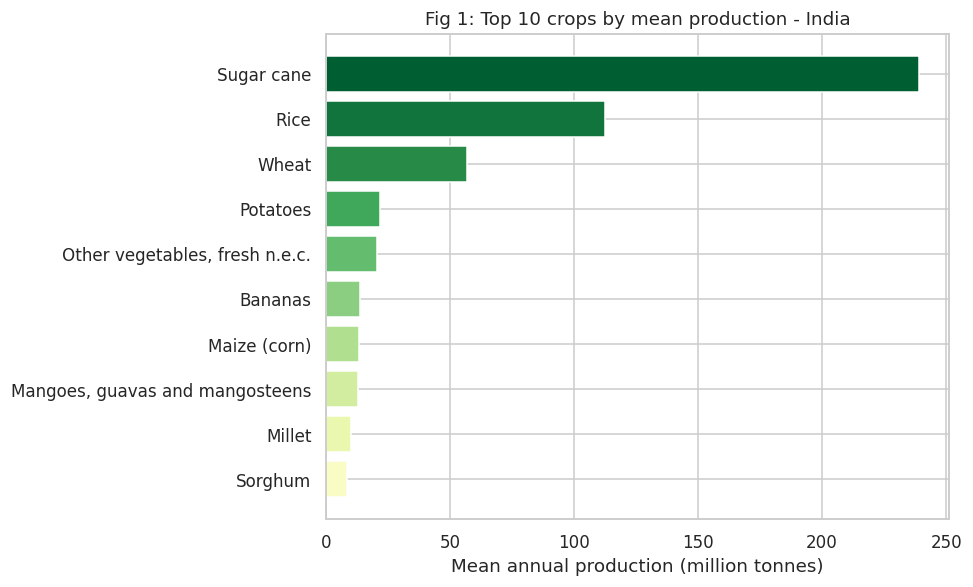

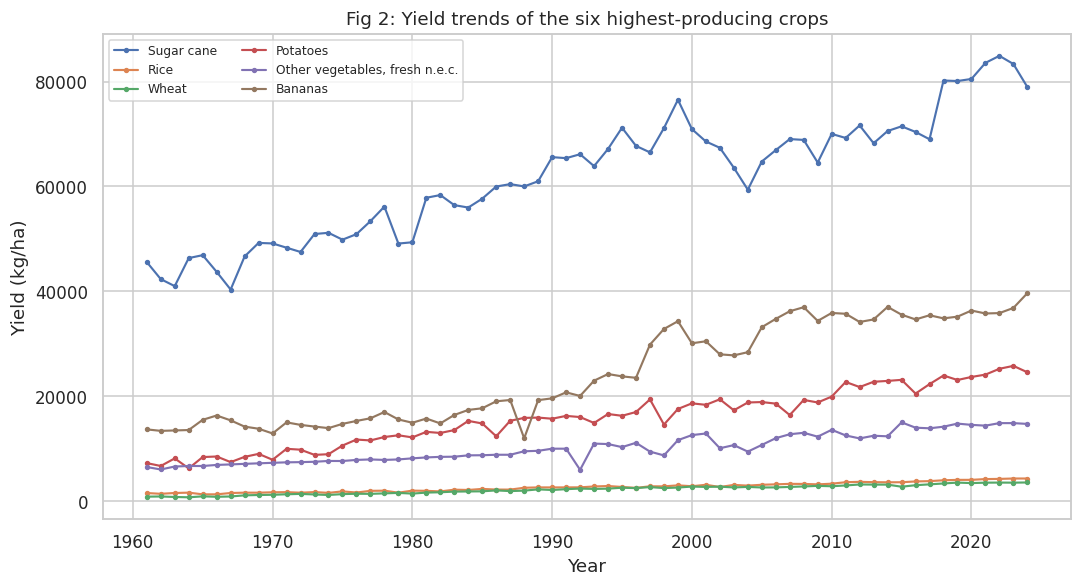

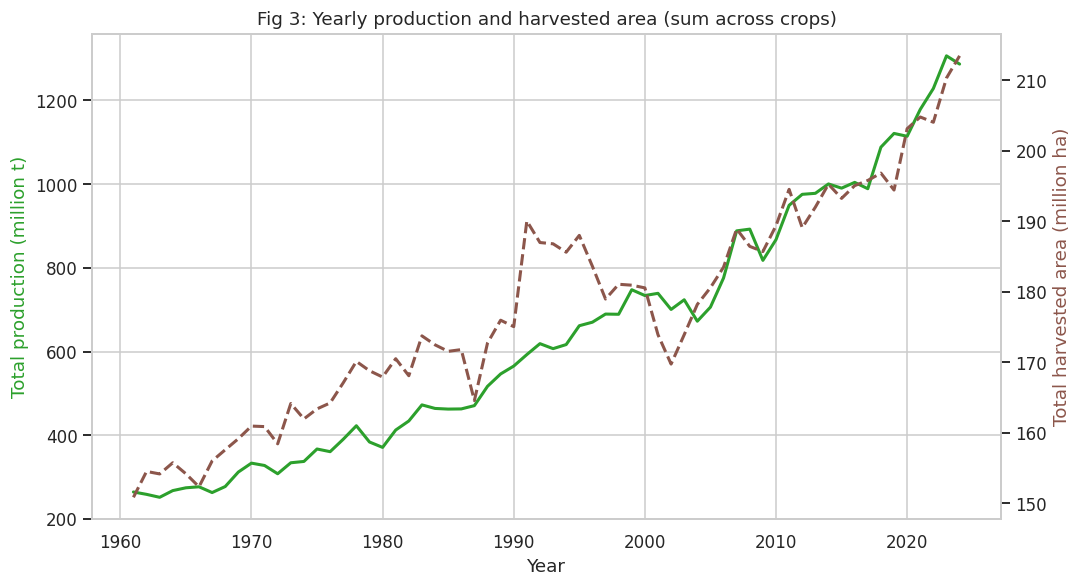

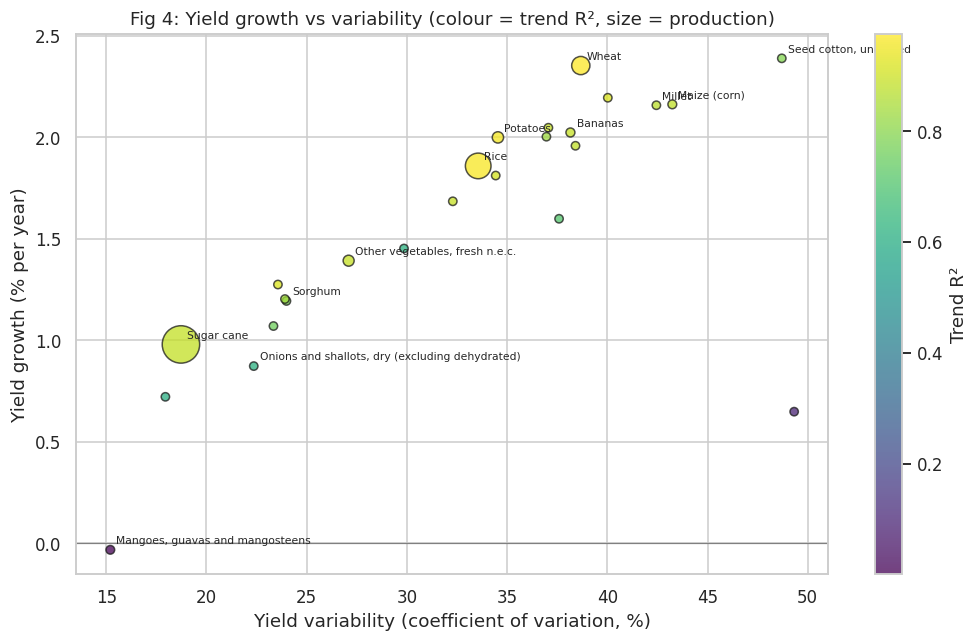

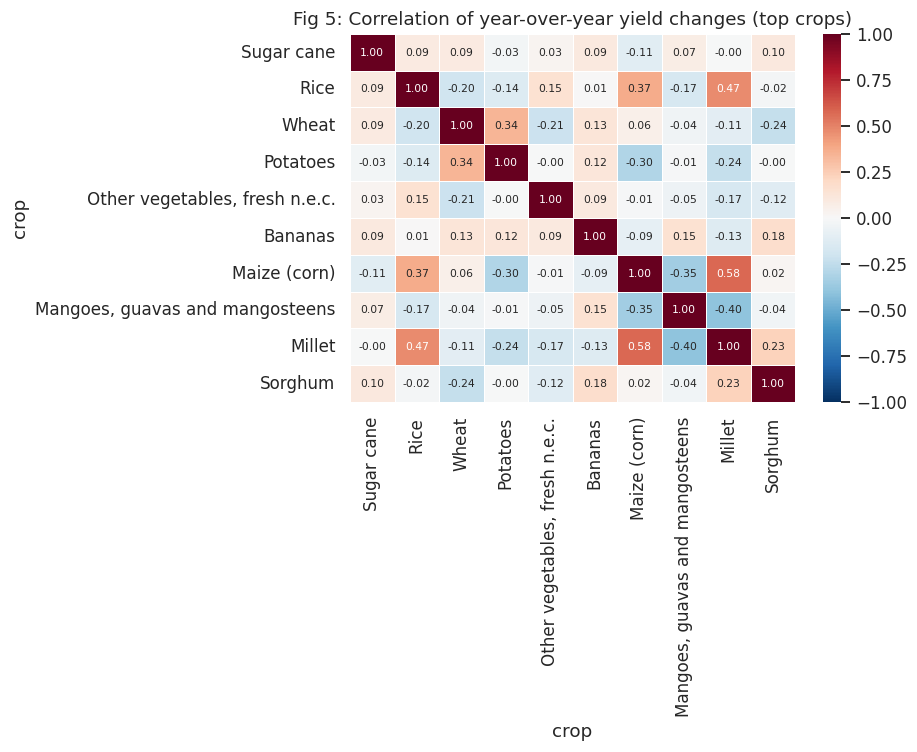

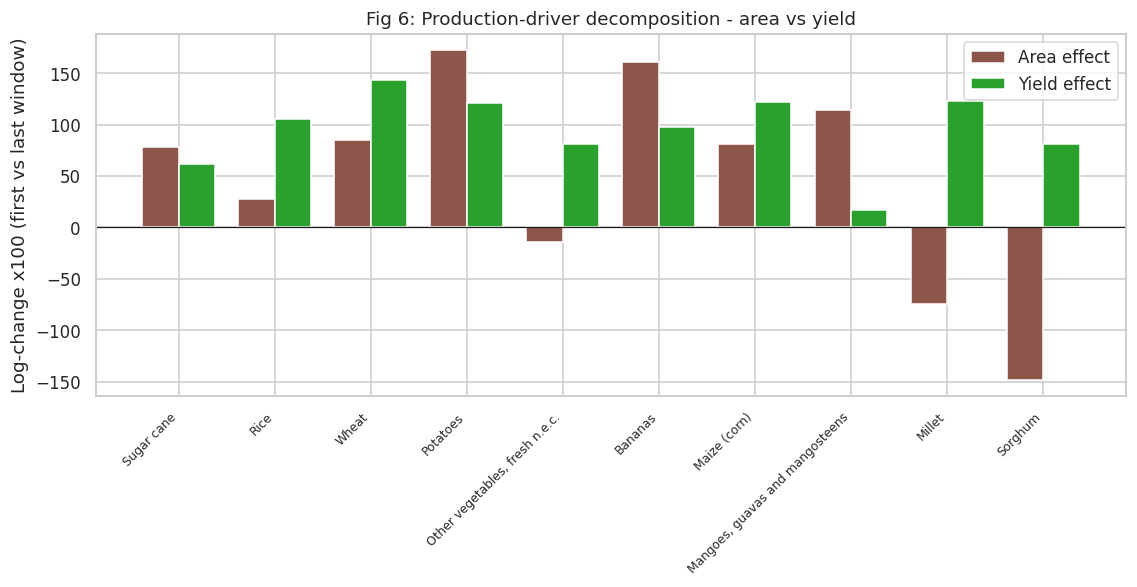

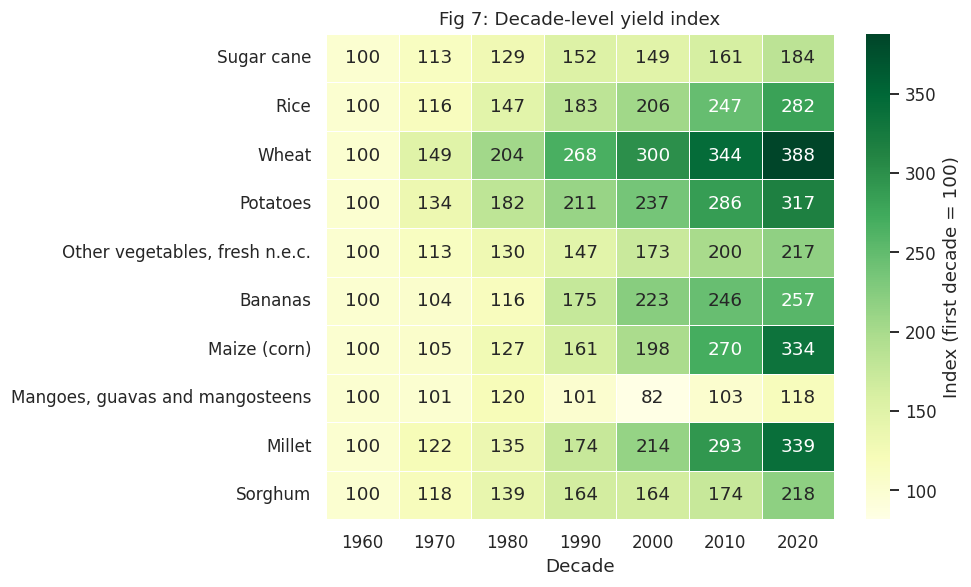

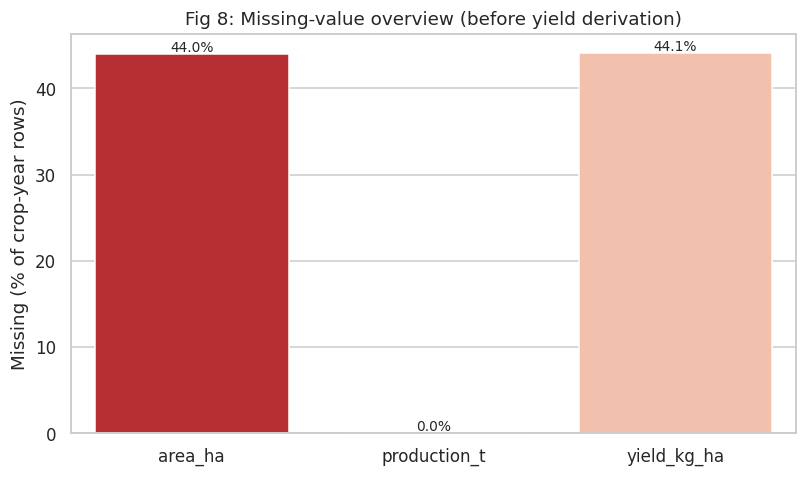

In [ ]:
def save_fig(fig, name):
    if TAG:
        fig.text(0.5, 0.005, TAG, ha="center", color="red", fontsize=9, weight="bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Figure 1 - top crops by mean production
top = crop_summary.head(TOP_N).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top["crop"], top["mean_production_t"] / 1e6, color=sns.color_palette("YlGn", len(top)))
ax.set_xlabel("Mean annual production (million tonnes)")
ax.set_title(f"Fig 1: Top {TOP_N} crops by mean production - {COUNTRY}")
save_fig(fig, "fig1_top_crop_production")

# Figure 2 - yield trend lines
fig, ax = plt.subplots(figsize=(10, 5.5))
for crop in top_crops[:6]:
    g = clean[clean.crop == crop]
    ax.plot(g["year"], g["yield_kg_ha"], marker="o", ms=2.5, lw=1.4, label=crop)
ax.set_xlabel("Year"); ax.set_ylabel("Yield (kg/ha)")
ax.set_title("Fig 2: Yield trends of the six highest-producing crops")
ax.legend(fontsize=8, ncol=2)
save_fig(fig, "fig2_yield_trends")

# Figure 3 - yearly production and harvested area
fig, ax1 = plt.subplots(figsize=(10, 5.5))
ax1.plot(yearly_totals["year"], yearly_totals["total_production_t"] / 1e6, color="tab:green", lw=2)
ax1.set_xlabel("Year"); ax1.set_ylabel("Total production (million t)", color="tab:green")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(yearly_totals["year"], yearly_totals["total_area_ha"] / 1e6, color="tab:brown", lw=2, ls="--")
ax2.set_ylabel("Total harvested area (million ha)", color="tab:brown")
ax1.set_title("Fig 3: Yearly production and harvested area (sum across crops)")
save_fig(fig, "fig3_yearly_production_area")

# Figure 4 - growth vs variability
cs = crop_summary.dropna(subset=["cv_pct", "yield_growth_pct_per_year"]).head(25)
fig, ax = plt.subplots(figsize=(9.5, 6))
sc = ax.scatter(cs["cv_pct"], cs["yield_growth_pct_per_year"],
                s=np.clip(cs["mean_production_t"] / cs["mean_production_t"].max() * 600, 30, 600),
                c=cs["trend_r2"], cmap="viridis", alpha=0.75, edgecolor="k")
for _, r in cs.head(12).iterrows():
    ax.annotate(r["crop"], (r["cv_pct"], r["yield_growth_pct_per_year"]), fontsize=7, xytext=(4, 4),
                textcoords="offset points")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Yield variability (coefficient of variation, %)")
ax.set_ylabel("Yield growth (% per year)")
ax.set_title("Fig 4: Yield growth vs variability (colour = trend R², size = production)")
fig.colorbar(sc, label="Trend R²")
save_fig(fig, "fig4_growth_variability")

# Figure 5 - yoy yield correlation
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(yoy_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.4, ax=ax, annot_kws={"size": 7})
ax.set_title("Fig 5: Correlation of year-over-year yield changes (top crops)")
save_fig(fig, "fig5_yield_yoy_correlation")

# Figure 6 - production drivers
pdv = production_drivers_df.head(TOP_N)
if len(pdv):
    x = np.arange(len(pdv)); w = 0.38
    fig, ax = plt.subplots(figsize=(10.5, 5.5))
    ax.bar(x - w/2, pdv["area_effect_logpts"], w, label="Area effect", color="tab:brown")
    ax.bar(x + w/2, pdv["yield_effect_logpts"], w, label="Yield effect", color="tab:green")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(pdv["crop"], rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("Log-change x100 (first vs last window)")
    ax.set_title("Fig 6: Production-driver decomposition - area vs yield")
    ax.legend()
    save_fig(fig, "fig6_production_drivers")

# Figure 7 - decade yield index
dec_pivot = (decade_yield[decade_yield.crop.isin(top_crops)]
             .pivot(index="crop", columns="decade", values="yield_index").reindex(top_crops))
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(dec_pivot, annot=True, fmt=".0f", cmap="YlGn", linewidths=0.4, ax=ax,
            cbar_kws={"label": "Index (first decade = 100)"})
ax.set_title("Fig 7: Decade-level yield index"); ax.set_xlabel("Decade"); ax.set_ylabel("")
save_fig(fig, "fig7_decade_yield_index")

# Figure 8 - missing values
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.barplot(data=missing_df, x="variable", y="missing_pct", palette="Reds_r", ax=ax)
for i, v in enumerate(missing_df["missing_pct"]):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_ylabel("Missing (% of crop-year rows)"); ax.set_xlabel("")
ax.set_title("Fig 8: Missing-value overview (before yield derivation)")
save_fig(fig, "fig8_missing_values")

## 6. SQLite Database & SQL Analysis
Star-style schema: `dim_crop`, `dim_year`, `fact_crop_year` with primary/foreign keys. Queries use aggregation, `RANK()`, `LAG()` and `ROW_NUMBER()` window functions.

In [ ]:
DB_PATH = DB_DIR / "agriculture.db"
if DB_PATH.exists():
    DB_PATH.unlink()

conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")
conn.executescript("""
CREATE TABLE dim_crop (
    crop_id   INTEGER PRIMARY KEY,
    crop_name TEXT NOT NULL UNIQUE
);
CREATE TABLE dim_year (
    year   INTEGER PRIMARY KEY,
    decade INTEGER NOT NULL
);
CREATE TABLE fact_crop_year (
    crop_id       INTEGER NOT NULL,
    year          INTEGER NOT NULL,
    area_ha       REAL,
    production_t  REAL,
    yield_kg_ha   REAL NOT NULL,
    yield_source  TEXT CHECK (yield_source IN ('reported','derived')),
    PRIMARY KEY (crop_id, year),
    FOREIGN KEY (crop_id) REFERENCES dim_crop(crop_id),
    FOREIGN KEY (year)    REFERENCES dim_year(year)
);
""")

dim_crop = pd.DataFrame({"crop_name": sorted(clean["crop"].unique())})
dim_crop.insert(0, "crop_id", range(1, len(dim_crop) + 1))
dim_year = pd.DataFrame({"year": sorted(clean["year"].unique())})
dim_year["decade"] = (dim_year["year"] // 10) * 10
fact = (clean.merge(dim_crop, left_on="crop", right_on="crop_name")
             [["crop_id", "year", "area_ha", "production_t", "yield_kg_ha", "yield_source"]])

dim_crop.to_sql("dim_crop", conn, if_exists="append", index=False)
dim_year.to_sql("dim_year", conn, if_exists="append", index=False)
fact.to_sql("fact_crop_year", conn, if_exists="append", index=False)
conn.commit()

fk_violations = conn.execute("PRAGMA foreign_key_check;").fetchall()
print("Tables loaded:", {t: conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
                         for t in ("dim_crop", "dim_year", "fact_crop_year")})
print("Foreign-key violations:", len(fk_violations))

Tables loaded: {'dim_crop': 84, 'dim_year': 64, 'fact_crop_year': 5020}
Foreign-key violations: 0


In [ ]:
SQL_QUERIES = {
"q1_top_crops_by_mean_production": """
    SELECT c.crop_name, ROUND(AVG(f.production_t), 0) AS mean_production_t,
           ROUND(AVG(f.yield_kg_ha), 1) AS mean_yield_kg_ha, COUNT(*) AS n_years
    FROM fact_crop_year f JOIN dim_crop c USING (crop_id)
    GROUP BY c.crop_name ORDER BY mean_production_t DESC LIMIT 10;""",

"q2_latest_year_yield_rank": """
    WITH latest AS (
        SELECT crop_id, MAX(year) AS yr FROM fact_crop_year GROUP BY crop_id)
    SELECT RANK() OVER (ORDER BY f.yield_kg_ha DESC) AS yield_rank,
           c.crop_name, f.year, ROUND(f.yield_kg_ha, 1) AS yield_kg_ha
    FROM fact_crop_year f
    JOIN latest l ON l.crop_id = f.crop_id AND l.yr = f.year
    JOIN dim_crop c ON c.crop_id = f.crop_id
    ORDER BY yield_rank LIMIT 15;""",

"q3_yoy_yield_change_top_swings": """
    WITH t AS (
        SELECT c.crop_name, f.year, f.yield_kg_ha,
               LAG(f.yield_kg_ha) OVER (PARTITION BY f.crop_id ORDER BY f.year) AS prev_yield
        FROM fact_crop_year f JOIN dim_crop c USING (crop_id))
    SELECT crop_name, year, ROUND(yield_kg_ha, 1) AS yield_kg_ha,
           ROUND((yield_kg_ha - prev_yield) * 100.0 / prev_yield, 2) AS yoy_change_pct
    FROM t WHERE prev_yield IS NOT NULL AND prev_yield > 0
    ORDER BY ABS(yoy_change_pct) DESC LIMIT 15;""",

"q4_decade_summary": """
    SELECT d.decade, COUNT(DISTINCT f.crop_id) AS n_crops,
           ROUND(AVG(f.yield_kg_ha), 1) AS mean_yield_kg_ha,
           ROUND(SUM(f.production_t) / COUNT(DISTINCT f.year) / 1e6, 2) AS avg_annual_production_mt
    FROM fact_crop_year f JOIN dim_year d USING (year)
    GROUP BY d.decade ORDER BY d.decade;""",

"q5_best_year_per_crop": """
    SELECT crop_name, year AS best_year, ROUND(yield_kg_ha, 1) AS best_yield_kg_ha FROM (
        SELECT c.crop_name, f.year, f.yield_kg_ha,
               ROW_NUMBER() OVER (PARTITION BY f.crop_id ORDER BY f.yield_kg_ha DESC) AS rn
        FROM fact_crop_year f JOIN dim_crop c USING (crop_id))
    WHERE rn = 1 ORDER BY best_yield_kg_ha DESC LIMIT 15;""",

"q6_data_quality_derived_yield": """
    SELECT c.crop_name,
           SUM(CASE WHEN f.yield_source = 'derived'  THEN 1 ELSE 0 END) AS derived_rows,
           SUM(CASE WHEN f.yield_source = 'reported' THEN 1 ELSE 0 END) AS reported_rows,
           SUM(CASE WHEN f.area_ha IS NULL OR f.production_t IS NULL THEN 1 ELSE 0 END) AS rows_missing_area_or_prod
    FROM fact_crop_year f JOIN dim_crop c USING (crop_id)
    GROUP BY c.crop_name
    HAVING derived_rows > 0 OR rows_missing_area_or_prod > 0
    ORDER BY derived_rows DESC LIMIT 15;""",
}

sql_results = {}
for name, q in SQL_QUERIES.items():
    res = pd.read_sql_query(q, conn)
    res.to_csv(SQL_DIR / f"{name}.csv", index=False)
    sql_results[name] = res
    print(f"\n=== {name} ===")
    display(res)


=== q1_top_crops_by_mean_production ===


,crop_name,mean_production_t,mean_yield_kg_ha,n_years
0,Sugar cane,"239,227,830.00","61,922.70",64
1,Rice,"112,294,445.00","2,643.20",64
2,Wheat,"56,760,745.00","2,194.60",64
3,Potatoes,"21,885,077.00","15,799.20",64
4,"Other vegetables, fresh n.e.c.","20,687,200.00","10,135.80",64
5,Bananas,"13,747,977.00","24,290.20",64
6,Maize (corn),"13,212,390.00","1,750.40",64
7,"Mangoes, guavas and mangosteens","12,904,085.00","8,432.90",64
8,Millet,"10,103,806.00",782.50,64
9,Sorghum,"8,381,686.00",755.00,64



=== q2_latest_year_yield_rank ===


,yield_rank,crop_name,year,yield_kg_ha
0,1,Sugar cane,2024,"78,953.00"
1,2,Bananas,2024,"39,658.00"
2,3,"Cassava, fresh",2024,"35,574.10"
3,4,Papayas,2024,"35,523.40"
4,5,Watermelons,2024,"29,115.30"
5,6,Yams,2024,"25,051.30"
6,7,Tomatoes,2024,"24,968.80"
7,8,Potatoes,2024,"24,568.40"
8,9,Pomelos and grapefruits,2016,"23,999.80"
9,10,Cabbages,2024,"23,583.40"



=== q3_yoy_yield_change_top_swings ===


,crop_name,year,yield_kg_ha,yoy_change_pct
0,"Other fruits, n.e.c.",2003,"35,770.20",758.33
1,Tea leaves,1991,"7,439.40",348.67
2,"Almonds, in shell",2013,428.60,135.75
3,"Almonds, in shell",2018,"1,293.30",121.15
4,"Pepper (Piper spp.), raw",2013,424.00,106.83
5,Cherries,1988,"1,600.00",96.63
6,Oranges,2004,"10,381.00",93.13
7,Cocoa beans,1994,567.40,89.13
8,Soya beans,1972,823.50,88.23
9,"Other vegetables, fresh n.e.c.",1993,"10,970.40",83.90


... (2 outputs left out)


=== q5_best_year_per_crop ===


,crop_name,best_year,best_yield_kg_ha
0,Sugar cane,2022,"84,906.30"
1,Yams,2014,"44,400.00"
2,Papayas,2017,"44,328.40"
3,Bananas,2024,"39,658.00"
4,"Cassava, fresh",2012,"38,581.80"
5,"Other fruits, n.e.c.",2003,"35,770.20"
6,Watermelons,2024,"29,115.30"
7,Grapes,2000,"28,250.00"
8,Tomatoes,2017,"25,982.40"
9,Potatoes,2023,"25,789.90"



=== q6_data_quality_derived_yield ===


,crop_name,derived_rows,reported_rows,rows_missing_area_or_prod


## 7. Power BI Exports
CSV files for Power BI: **Get Data → Text/CSV**, load all files from `powerbi/data/`, then create relationships
`fact_crop_year[crop_id] → dim_crop[crop_id]` and `fact_crop_year[year] → dim_year[year]`.

In [ ]:
dim_crop.to_csv(PBI_DIR / "dim_crop.csv", index=False)
dim_year.to_csv(PBI_DIR / "dim_year.csv", index=False)
fact.to_csv(PBI_DIR / "fact_crop_year.csv", index=False)
crop_summary.to_csv(PBI_DIR / "crop_summary.csv", index=False)
yearly_totals.to_csv(PBI_DIR / "yearly_totals.csv", index=False)
decade_yield.to_csv(PBI_DIR / "decade_yield.csv", index=False)
production_drivers_df.to_csv(PBI_DIR / "production_drivers.csv", index=False)

(PBI_DIR.parent / "README_PowerBI.md").write_text("""# Power BI Dashboard Guide
1. Open Power BI Desktop -> Get Data -> Text/CSV; load every CSV in `data/`.
2. Model view: dim_crop[crop_id] 1-* fact_crop_year[crop_id]; dim_year[year] 1-* fact_crop_year[year].
3. Suggested visuals: line chart (yield by year, legend = crop), bar chart (top crops by production),
   decade heat-map (decade_yield), scatter (crop_summary: CV vs yield growth), slicers for crop & decade.
""")
print("Power BI files:", sorted(p.name for p in PBI_DIR.glob("*.csv")))

Power BI files: ['crop_summary.csv', 'decade_yield.csv', 'dim_crop.csv', 'dim_year.csv', 'fact_crop_year.csv', 'production_drivers.csv', 'yearly_totals.csv']


## 8. Auto-generated Analysis Summary

In [ ]:
def build_summary():
    cs = crop_summary
    sig_up = cs[(cs.trend_p_value < 0.05) & (cs.trend_slope_kg_ha_per_year > 0)]
    sig_dn = cs[(cs.trend_p_value < 0.05) & (cs.trend_slope_kg_ha_per_year < 0)]
    fastest = cs.sort_values("yield_growth_pct_per_year", ascending=False).iloc[0]
    volatile = cs.sort_values("cv_pct", ascending=False).iloc[0]
    stable = cs.sort_values("cv_pct").iloc[0]
    top1 = cs.iloc[0]
    derived = int((clean.yield_source == "derived").sum())

    lines = []
    if TAG:
        lines += [f"> **WARNING: {TAG}**", ""]
    lines += [
        f"# Analysis Summary - {COUNTRY}", "",
        f"* **Source file:** `{Path(raw_file).name}`",
        f"* **Period covered:** {clean.year.min()}-{clean.year.max()}",
        f"* **Crops analysed:** {clean.crop.nunique()} (minimum {MIN_YEARS} yield years each)",
        f"* **Crop-year records:** {len(clean):,}  (yield derived for {derived:,} records)", "",
        "## Key descriptive findings",
        f"* Highest mean annual production: **{top1.crop}** ({top1.mean_production_t/1e6:,.2f} million t).",
        f"* Fastest yield growth (log-linear): **{fastest.crop}** ({fastest.yield_growth_pct_per_year:.2f}% per year).",
        f"* Most volatile yield: **{volatile.crop}** (CV {volatile.cv_pct:.1f}%); most stable: **{stable.crop}** (CV {stable.cv_pct:.1f}%).",
        f"* Crops with a statistically significant (p<0.05) upward yield trend: **{len(sig_up)}** of {len(cs)}; downward: **{len(sig_dn)}**.",
    ]
    if len(production_drivers_df):
        dom = production_drivers_df["dominant_driver"].value_counts()
        lines.append("* Dominant production driver across crops: " +
                     ", ".join(f"{k} ({v})" for k, v in dom.items()) + ".")
    lines += ["", "## Caveats",
              "* Trends are descriptive and do not establish causation.",
              "* National averages hide regional/seasonal variation.",
              "* Yearly totals add different crops together and are indicative only.",
              "* Verify selected values against FAOSTAT and review `cleaning_report.csv` and `excluded_items.csv`."]
    return "\n".join(lines)

summary_md = build_summary()
(OUT_DIR / "analysis_summary.md").write_text(summary_md, encoding="utf-8")
display(Markdown(summary_md))

# Analysis Summary - India

* **Source file:** `Production_Crops_Livestock_E_All_Data_(Normalized).csv`
* **Period covered:** 1961-2024
* **Crops analysed:** 84 (minimum 10 yield years each)
* **Crop-year records:** 5,020  (yield derived for 0 records)

## Key descriptive findings
* Highest mean annual production: **Sugar cane** (239.23 million t).
* Fastest yield growth (log-linear): **Almonds, in shell** (11.81% per year).
* Most volatile yield: **Nutmeg, mace, cardamoms, raw** (CV 83.2%); most stable: **Apricots** (CV 3.6%).
* Crops with a statistically significant (p<0.05) upward yield trend: **73** of 84; downward: **5**.
* Dominant production driver across crops: Area (56), Yield (28).

## Caveats
* Trends are descriptive and do not establish causation.
* National averages hide regional/seasonal variation.
* Yearly totals add different crops together and are indicative only.
* Verify selected values against FAOSTAT and review `cleaning_report.csv` and `excluded_items.csv`.

## 9. Download Everything

In [ ]:
conn.close()
zip_base = "agriculture_project_outputs"
archive = shutil.make_archive(zip_base, "zip", root_dir=BASE.parent, base_dir=BASE.name)
print("Created:", archive)

if IN_COLAB:
    files.download(archive)
else:
    print("Not in Colab - find the ZIP in the working directory.")

Created: /content/agriculture_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>